In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)


All libraries imported successfully!
Pandas version: 3.0.3
Scikit-learn version: 1.9.0


In [11]:
data = {
    "Study_Hours": [
        1, 2, 3, 4, 5, 6, 7, 8, 2, 3,
        4, 5, 6, 7, 8, 1, 2, 3, 5, 6,
        7, 8, 1, 4, 5, 6, 7, 3, 8, 2,
        4, 5, 6, 7, 8, 1, 3, 4, 6, 7
    ],
    "Attendance": [
        50, 55, 60, 65, 70, 75, 80, 90, 60, 65,
        70, 75, 85, 90, 95, 45, 55, 60, 72, 80,
        85, 95, 40, 68, 78, 82, 88, 62, 98, 52,
        72, 76, 84, 92, 96, 48, 64, 70, 86, 90
    ],
    "Previous_Score": [
        35, 40, 45, 50, 55, 60, 70, 85, 42, 48,
        52, 58, 65, 75, 90, 30, 38, 44, 60, 68,
        78, 88, 25, 50, 62, 72, 80, 46, 92, 36,
        54, 64, 70, 82, 94, 28, 48, 56, 74, 86
    ],
    "Result": [
        "Fail", "Fail", "Fail", "Fail", "Pass",
        "Pass", "Pass", "Pass", "Fail", "Fail",
        "Fail", "Pass", "Pass", "Pass", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass",
        "Pass", "Pass", "Fail", "Fail", "Pass",
        "Pass", "Pass", "Fail", "Pass", "Fail",
        "Fail", "Pass", "Pass", "Pass", "Pass",
        "Fail", "Fail", "Fail", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset created successfully!
Dataset shape: (40, 4)


,Study_Hours,Attendance,Previous_Score,Result
0,1,50,35,Fail
1,2,55,40,Fail
2,3,60,45,Fail
3,4,65,50,Fail
4,5,70,55,Pass
5,6,75,60,Pass
6,7,80,70,Pass
7,8,90,85,Pass
8,2,60,42,Fail
9,3,65,48,Fail


In [12]:
# Check dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStudent Result Counts:")
print(df["Result"].value_counts())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     40 non-null     int64
 1   Attendance      40 non-null     int64
 2   Previous_Score  40 non-null     int64
 3   Result          40 non-null     str  
dtypes: int64(3), str(1)
memory usage: 1.5 KB

Missing Values:
Study_Hours       0
Attendance        0
Previous_Score    0
Result            0
dtype: int64

Duplicate Rows:
0

Student Result Counts:
Result
Pass    22
Fail    18
Name: count, dtype: int64

Statistical Summary:


,Study_Hours,Attendance,Previous_Score
count,40.000000,40.000000,40.000000
mean,4.750000,73.075000,59.875000
std,2.250356,15.509116,19.023855
min,1.000000,40.000000,25.000000
25%,3.000000,61.500000,45.750000
50%,5.000000,73.500000,59.000000
75%,7.000000,85.250000,74.250000
max,8.000000,98.000000,94.000000


In [13]:
from sklearn.model_selection import train_test_split

# Features: information used to make predictions
X = df[["Study_Hours", "Attendance", "Previous_Score"]]

# Target: what we want to predict
y = df["Result"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Data split successfully!")
print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Data split successfully!
Total records: 40
Training records: 30
Testing records: 10

Training features shape: (30, 3)
Testing features shape: (10, 3)


In [14]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree Model trained successfully!")
print("Model is ready to predict student results.")

Decision Tree Model trained successfully!
Model is ready to predict student results.


In [15]:
from sklearn.metrics import accuracy_score, classification_report

# Predict results using test data
y_pred = model.predict(X_test)

# Compare predictions with actual results
accuracy = accuracy_score(y_test, y_pred)

print("Actual Results:")
print(y_test.to_list())

print("\nPredicted Results:")
print(y_pred.tolist())

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Actual Results:
['Fail', 'Fail', 'Pass', 'Fail', 'Pass', 'Fail', 'Pass', 'Pass', 'Pass', 'Fail']

Predicted Results:
['Pass', 'Fail', 'Fail', 'Fail', 'Pass', 'Fail', 'Pass', 'Pass', 'Pass', 'Fail']

Model Accuracy: 80.0 %

Classification Report:
              precision    recall  f1-score   support

        Fail       0.80      0.80      0.80         5
        Pass       0.80      0.80      0.80         5

    accuracy                           0.80        10
   macro avg       0.80      0.80      0.80        10
weighted avg       0.80      0.80      0.80        10



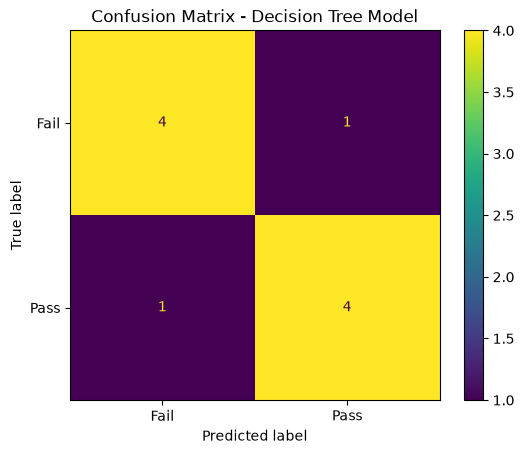

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])

# Display the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)

display_matrix.plot()
plt.title("Confusion Matrix - Decision Tree Model")
plt.show()

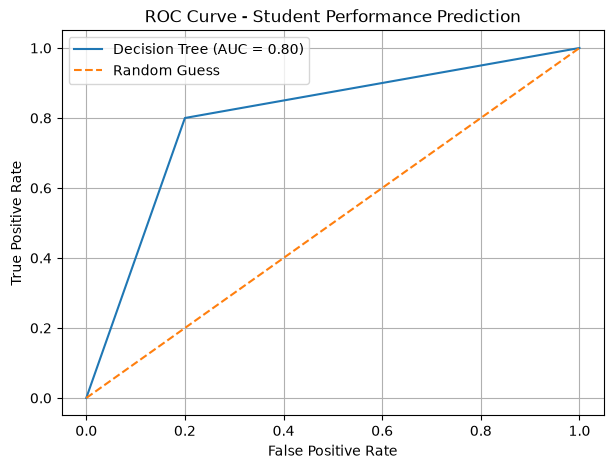

AUC Score: 0.8


In [17]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get the probability of the "Pass" class
y_prob = model.predict_proba(X_test)[:, 
    list(model.classes_).index("Pass")
]

# Convert actual results into binary values
y_test_binary = (y_test == "Pass").astype(int)

# Calculate ROC curve and AUC score
fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)
auc_score = roc_auc_score(y_test_binary, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Student Performance Prediction")
plt.legend()
plt.grid(True)
plt.show()

print("AUC Score:", round(auc_score, 3))

Feature Importance:


,Feature,Importance
1,Attendance,1.0
0,Study_Hours,0.0
2,Previous_Score,0.0


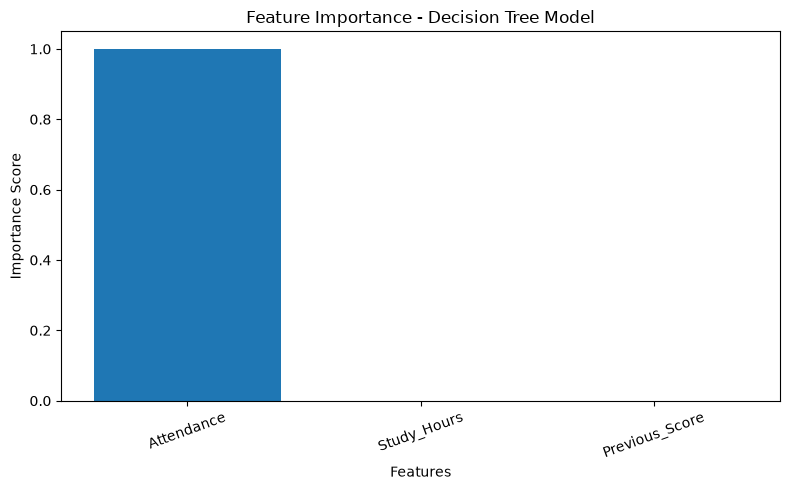

In [18]:
# Get feature importance from the trained model
importance = model.feature_importances_

# Create a DataFrame for visualization
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance_df)

# Plot the feature importance
plt.figure(figsize=(8, 5))
plt.bar(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.title("Feature Importance - Decision Tree Model")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()